In [1]:
import os
os.chdir('/home/jiangwenbin/shared/workspace/AlphaCore/examples/voicebank')
print(os.getcwd())

/home/jiangwenbin/shared/workspace/AlphaCore/examples/voicebank


In [2]:
import shutil
from pathlib import Path
import librosa
import numpy as np
import librosa.display
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.stats import ttest_ind

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import seaborn
seaborn.set(style="whitegrid", font_scale=1.2)
plt.rcParams['axes.grid'] = False

import sys
sys.path.append("../../")
from modules.utils import metrics
save_dir = Path('exp/paper/SelfSE')

In [ ]:
list(set([x for x in id_list if id_list.count(x) > 1]))

In [ ]:
wav_dir = Path('~/shared/workspace/AlphaSE').expanduser()

id_list = ['p257_008', 'p257_033', 'p257_106', 'p232_250','p232_409', 
           'p232_394', 'p232_373', 'p232_312', 'p257_038', 'p232_068', 
           'p257_118', 'p257_287', 'p257_279', 'p232_382', 'p257_022', 
           'p257_086', 'p232_040', 'p232_361', 'p232_291', 'p257_235']

wav_list = [("exp/logs_self/ComplexSE_DCCRN/3a0/clean/{}.wav", "Clean"),
            ("exp/logs_self/ComplexSE_DCCRN/3a0/noisy/{}.wav", "Noisy"),
            ("exp/denoise/OMLSA_voicebank_testset/{}.wav", "OMLSA"),
            ("exp/denoise/DCCRN_voicebank/{}.wav", "DCCRN"),
            ("exp/logs_self/N2N_ComplexSE_DCUNet/3a0/est/{}.wav", "Noise2Noise"),
            ("exp/logs_self/N2N_UniSE_UNet/3a1/est/{}.wav", "NyTT"),
            ("exp/logs_self/N2N_UniSE_UNet/3a6/est/{}.wav", "IDR"),
            ("exp/logs_self/N2N_UniSE_UNet/3b15/est/{}.wav", "IterSE")]

for file_idx in id_list:
    for (wav, method) in wav_list:
        wav_path = wav_dir.joinpath(wav.format(file_idx))
        if method == 'Clean':
            clean, _ = librosa.load(wav_path, sr=None)
            continue
        y, sr = librosa.load(wav_path, sr=None)
        ref, est = clean, y
        est = est[:ref.shape[0]]
        ref = ref[:est.shape[0]]
        score = metrics.eval(ref, est, sr)
        print(file_idx, method, score)
    print("-"*60)

In [ ]:
for file_idx in id_list:
    for (wav, method) in wav_list:
        wav_path = wav_dir.joinpath(wav.format(file_idx))
        dest_dir = save_dir.joinpath(f"samples/{method}")
        dest_dir.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(wav_path, dest_dir.joinpath(wav_path.name))

## mushra

In [4]:
csv_path = Path("exp/results/mushra.csv")
df = pd.read_csv(csv_path)
df['trial_id'] = df['trial_id'].apply(lambda x: x[6:])
df = df.drop(['session_test_id', 'rating_comment', 'rating_time'], axis=1)
df['MOS'] = df['rating_stimulus'].apply(lambda x: x[:7])
df['method'] = df['rating_stimulus'].apply(lambda x: x[8:])
df = df[df['name'] != 'test']
# df['rating_score'] = df['rating_score'].replace(0, 20) # 异常值0分提升为10分
# df.loc[df['rating_score'] < 40, 'rating_score'] = 40
df['rating_score'] = df['rating_score'].apply(lambda x: float(x)/25.0+1)
df

,name,trial_id,rating_stimulus,rating_score,MOS,method
0,李锦,p232_250,OVL-MOS-Noise2Noise,4.40,OVL-MOS,Noise2Noise
1,李锦,p232_250,SIG-MOS-Noise2Noise,4.32,SIG-MOS,Noise2Noise
2,李锦,p232_250,BAK-MOS-Noise2Noise,3.96,BAK-MOS,Noise2Noise
3,李锦,p232_250,OVL-MOS-NyTT,2.32,OVL-MOS,NyTT
4,李锦,p232_250,SIG-MOS-NyTT,3.64,SIG-MOS,NyTT
...,...,...,...,...,...,...
13015,任博宏,p232_291,SIG-MOS-OMLSA,4.76,SIG-MOS,OMLSA
13016,任博宏,p232_291,BAK-MOS-OMLSA,5.00,BAK-MOS,OMLSA
13017,任博宏,p232_291,OVL-MOS-IDR,3.24,OVL-MOS,IDR
13018,任博宏,p232_291,SIG-MOS-IDR,4.04,SIG-MOS,IDR


In [32]:
df['method'] = df['method'].replace({'IDR': 'IDR-SE', 'IterSE': 'SelfSE'})

In [ ]:
# df = df[~df['name'].isin(['方俊浩', '陈文韬', '凌锋', '鲍朝鑫', '戎昊'])]

In [33]:
print(len(df['name'].unique()), df['name'].unique())

31 ['李锦' 'wbjiang' 'xuanhaoCai' '张豪' '牟宣溥' '吴开颖' '王相博' '田益韬' '张雯' '张杨' '方俊浩'
 '李凯' '张智强' '石云飞' '陈文韬' '王嘉杰' '邵锦程' '凌锋' '李' '魏婕' '鲍朝鑫' '胡鑫' '柴古蜚' '钱景瑞'
 '戎昊' '陈博洋' '沈靖凯' '周禹含' '方欣雨' '尤禹博' '任博宏']


In [34]:
df[df['MOS'] == 'OVL-MOS'].groupby('method')['rating_score'].mean().sort_values(ascending=False)

method
DCCRN          4.549935
Noise2Noise    4.431032
SelfSE         4.329871
OMLSA          4.207548
IDR-SE         3.862581
NyTT           3.546774
Noisy          3.465161
Name: rating_score, dtype: float64

In [35]:
df[df['MOS'] == 'SIG-MOS'].groupby('method')['rating_score'].mean().sort_values(ascending=False)

method
DCCRN          4.727290
OMLSA          4.674968
Noise2Noise    4.652516
SelfSE         4.632129
IDR-SE         4.386968
NyTT           4.386581
Noisy          4.343935
Name: rating_score, dtype: float64

In [36]:
df[df['MOS'] == 'BAK-MOS'].groupby('method')['rating_score'].mean().sort_values(ascending=False)

method
DCCRN          4.497548
Noise2Noise    4.388645
SelfSE         4.283613
OMLSA          4.119935
IDR-SE         3.783097
NyTT           3.391806
Noisy          3.308968
Name: rating_score, dtype: float64

In [38]:
name_list = ["Noisy", "OMLSA", "DCCRN", "Noise2Noise", "NyTT", "IDR-SE", "SelfSE"]
MOS_list = ["SIG-MOS", "BAK-MOS", "OVL-MOS"]
def calc_CI(data, ci=0.95):
    data = data.to_numpy()
    CI = stats.norm.interval(ci, loc=data.mean(), scale=stats.sem(data))
    return (CI[1] - CI[0])/2

for i, name in enumerate(name_list):
    data_list = []
    print(f"{name}:")
    for j, item in enumerate(MOS_list):      
        data = df[(df['MOS']==item) & (df['method']==name)]['rating_score']
        print("[{}] {:.2f} {:.2f} ".format(item, data.mean(), calc_CI(data)), end="")
    print("")

Noisy:
[SIG-MOS] 4.34 0.07 [BAK-MOS] 3.31 0.08 [OVL-MOS] 3.47 0.09 
OMLSA:
[SIG-MOS] 4.67 0.04 [BAK-MOS] 4.12 0.07 [OVL-MOS] 4.21 0.07 
DCCRN:
[SIG-MOS] 4.73 0.03 [BAK-MOS] 4.50 0.04 [OVL-MOS] 4.55 0.04 
Noise2Noise:
[SIG-MOS] 4.65 0.04 [BAK-MOS] 4.39 0.05 [OVL-MOS] 4.43 0.04 
NyTT:
[SIG-MOS] 4.39 0.06 [BAK-MOS] 3.39 0.08 [OVL-MOS] 3.55 0.08 
IDR-SE:
[SIG-MOS] 4.39 0.06 [BAK-MOS] 3.78 0.07 [OVL-MOS] 3.86 0.07 
SelfSE:
[SIG-MOS] 4.63 0.04 [BAK-MOS] 4.28 0.05 [OVL-MOS] 4.33 0.05 


## 画图

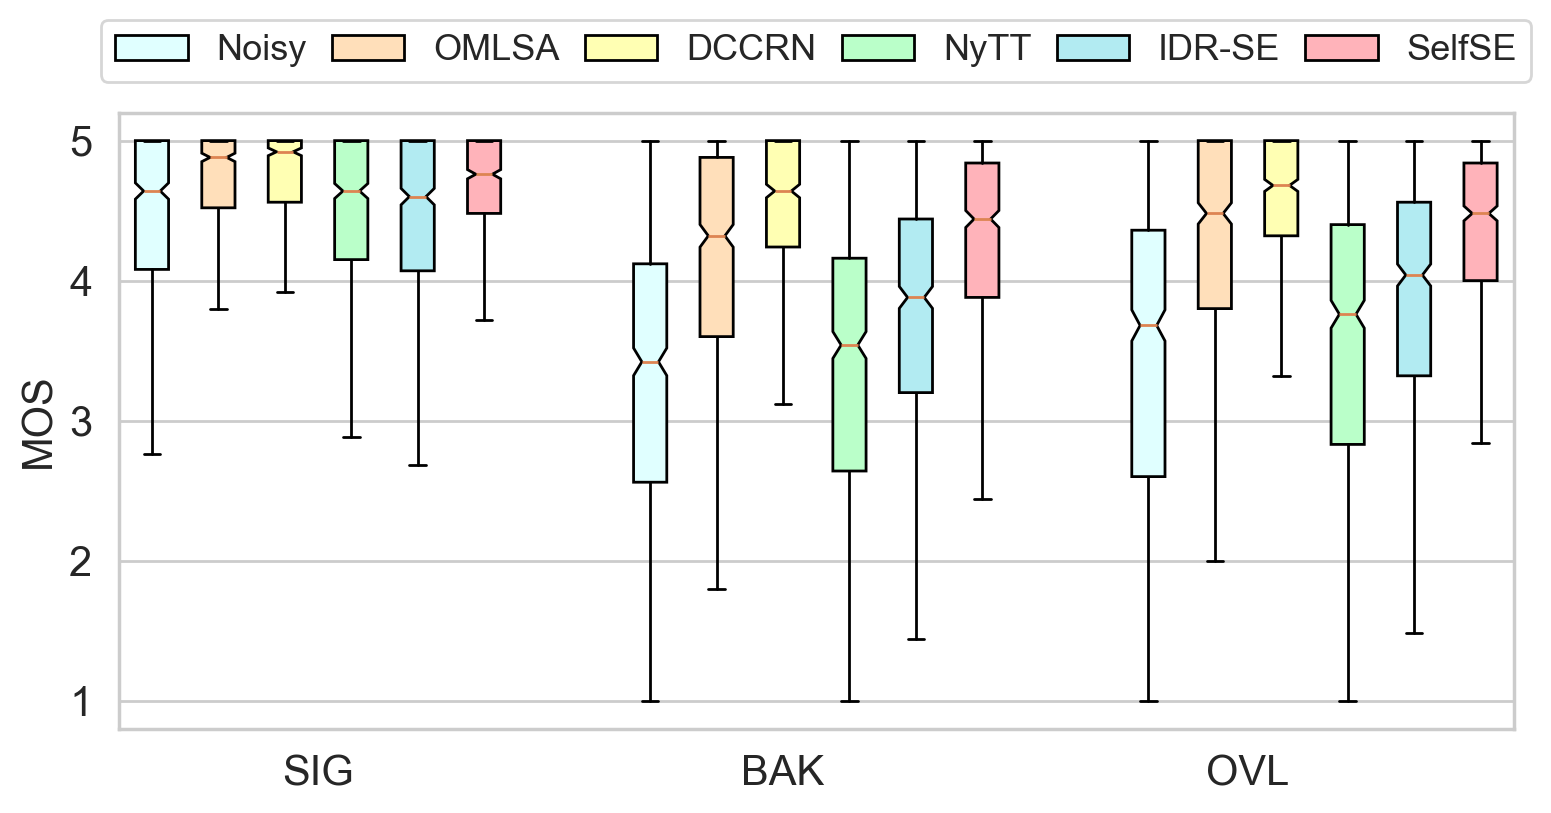

In [42]:
name_list = ["Noisy", "OMLSA", "DCCRN", "NyTT", "IDR-SE", "SelfSE"]
MOS_list = ["SIG-MOS", "BAK-MOS", "OVL-MOS"]
# colors = ['whitesmoke', 'lightyellow', 'lightblue', 'lightgreen', 'lightsalmon', 'lightpink']
# colors = ['whitesmoke', 'lightyellow', 'lightblue', 'lightgreen', 'lightsalmon', 'lightpink', 'lavender']
# colors = ['#ADD8E6', '#FFB6C1', '#FFFF99', '#FFDAB9', '#E0FFFF', '#FFB347', '#C7E9B0']
# colors = ['#E0FFFF', '#FFDFBA', '#FFFFBA', '#BAFFC9', '#BAE1FF', '#FFB3BA']
colors = ['#E0FFFF', '#FFDFBA', '#FFFFB3', '#BAFFC9', '#B2EBF2', '#FFB3BA']

figsize = (9, 4)
group_spacing = 1.5  # 组间间距
box_spacing = 1  # 组内间距
# 计算每个组的位置
group_positions = np.arange(len(MOS_list)) * (group_spacing + box_spacing * len(name_list))
fig, ax = plt.subplots(figsize=figsize)
bp_list = []

for i, name in enumerate(name_list):
    data_list = []
    positions = group_positions + i * box_spacing  # 每个组内的位置
    for j, item in enumerate(MOS_list):
        # 模拟数据加载
        # data = np.random.rand(10)  # 替换为实际数据
        data = df[(df['MOS']==item) & (df['method']==name)]['rating_score'].tolist()
        data_list.append(data)
    bp = plt.boxplot(data_list, positions=positions, showfliers=False, widths=0.5,
                     notch=True, patch_artist=True, boxprops=dict(facecolor=colors[i % len(colors)]))
    bp_list.append(bp)
    
ax.legend([item["boxes"][0] for item in bp_list], name_list, 
          loc='upper center', ncol=6, fontsize=13, columnspacing=0.7, bbox_to_anchor=(0.5,1.18))
plt.xticks(size=15)
plt.yticks(size=15)
ax.set_yticks(range(1,6))
plt.ylabel("MOS", fontsize=15)
plt.xticks([2.5, 9.5, 16.5], ['SIG', 'BAK', 'OVL'], fontsize=15)
ax.yaxis.grid(True)
ax.xaxis.grid(False)
plt.savefig(f"exp/debug/MOS.png", dpi=220, bbox_inches='tight')
plt.show()